# Phân tích dữ liệu Bank Marketing

Phân tích so sánh kết quả đăng ký tiền gửi theo tuổi, tình trạng vay nhà, lịch sử chiến dịch và số dư, từ đó đề xuất hướng thử nghiệm marketing. Dữ liệu: [Bank Marketing Dataset trên Kaggle](https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset).

Đặt `bank.csv` cạnh notebook khi chạy trên Jupyter. Trên Colab, kết nối Drive hoặc tải file lên khi được yêu cầu.

In [1]:
# Kết nối Drive hoặc chọn file dữ liệu
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

data_path = Path('bank.csv')
if 'google.colab' in sys.modules:
    from google.colab import drive, files
    drive_path = Path('/content/drive/MyDrive/bank.csv')
    try:
        drive.mount('/content/drive')
    except Exception as exc:
        print(f'Không kết nối được Drive: {exc}')
    if drive_path.is_file():
        data_path = drive_path
    elif not data_path.is_file():
        print('Chọn file bank.csv để tải lên Colab.')
        uploaded = files.upload()
        if 'bank.csv' not in uploaded:
            raise FileNotFoundError('Hãy tải lên đúng file bank.csv.')
elif not data_path.is_file():
    data_path = Path(input('Nhập đường dẫn tới bank.csv: ').strip()).expanduser()

if not data_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {data_path}')
df = pd.read_csv(data_path)
expected_columns = 'age job marital education default balance housing loan contact day month duration campaign pdays previous poutcome deposit'.split()
missing_columns = sorted(set(expected_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f'Thiếu các cột dữ liệu: {missing_columns}')
if df.empty or not df['deposit'].isin(['yes', 'no']).all():
    raise ValueError('Dữ liệu phải có bản ghi và deposit chỉ nhận yes hoặc no.')
pd.set_option('display.max_columns', None)
print('Đọc dữ liệu từ:', data_path)
print('Kích thước:', df.shape)
display(df.head())

Đọc dữ liệu từ: bank.csv
Kích thước: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## 1. Thu thập và đánh giá dữ liệu

Dữ liệu gồm 11.162 bản ghi và 17 thuộc tính:

- Cá nhân: `age`, `job`, `marital`, `education`.
- Tài chính: `balance`, `housing`, `loan`, `default`.
- Liên hệ và lịch sử chiến dịch: `contact`, `day`, `month`, `duration`, `campaign`, `pdays`, `previous`, `poutcome`.
- Kết quả: `deposit` (`yes` hoặc `no`).

`duration` chỉ được biết sau cuộc gọi nên không dùng để chọn khách hàng trước khi gọi.

In [2]:
# Kiểm tra cấu trúc, giá trị thiếu và các nhãn chưa biết
print('Kiểu dữ liệu và số giá trị không thiếu:')
df.info()
quality = pd.DataFrame({'Kiểu': df.dtypes.astype(str), 'Thiếu': df.isna().sum(), 'Thiếu (%)': df.isna().mean() * 100,
                        'Số giá trị khác nhau': df.nunique()})
display(quality)
print('Số dòng trùng hoàn toàn:', df.duplicated().sum())
print('Số giá trị unknown theo cột:')
unknown_counts = (df == 'unknown').sum()
display(unknown_counts[unknown_counts > 0])
display(df.describe().T)

Kiểu dữ liệu và số giá trị không thiếu:
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB
Số dòng trùng hoàn toàn: 0
Số giá trị unknown theo cột:


,Kiểu,Thiếu,Thiếu (%),Số giá trị khác nhau
age,int64,0,0.0,76
job,str,0,0.0,12
marital,str,0,0.0,3
education,str,0,0.0,4
default,str,0,0.0,2
balance,int64,0,0.0,3805
housing,str,0,0.0,2
loan,str,0,0.0,2
contact,str,0,0.0,3
day,int64,0,0.0,31


job            70
education     497
contact      2346
poutcome     8326
dtype: int64

,count,mean,std,min,25%,50%,75%,max
age,11162.0,41.231948,11.913369,18.0,32.0,39.0,49.00,95.0
balance,11162.0,1528.538524,3225.413326,-6847.0,122.0,550.0,1708.00,81204.0
day,11162.0,15.658036,8.420740,1.0,8.0,15.0,22.00,31.0
duration,11162.0,371.993818,347.128386,2.0,138.0,255.0,496.00,3881.0
campaign,11162.0,2.508421,2.722077,1.0,1.0,2.0,3.00,63.0
pdays,11162.0,51.330407,108.758282,-1.0,-1.0,-1.0,20.75,854.0
previous,11162.0,0.832557,2.292007,0.0,0.0,0.0,1.00,58.0


## 2. Tiền xử lý và làm sạch dữ liệu

Giữ `unknown` thành nhóm riêng để tránh gán thông tin chưa xác minh. Mã `pdays = -1` biểu thị chưa liên hệ trong chiến dịch trước.

IQR = Q3 − Q1 dựa trên phân vị, ít chịu ảnh hưởng của giá trị cực đoan. Các điểm ngoài khoảng [Q1 − 1,5 × IQR; Q3 + 1,5 × IQR] được đánh dấu để rà soát. Chúng được giữ lại vì chưa có bằng chứng là dữ liệu sai.

Biến chỉ báo đăng ký và nhóm tuổi phục vụ tính tỷ lệ. Phân tích theo nhóm không yêu cầu chuẩn hóa các biến số.

In [3]:
# Kiểm tra miền giá trị và xử lý bản ghi trùng
print('Giá trị deposit:', df['deposit'].value_counts(dropna=False).to_dict())
print('Tuổi ngoài 18–100:', (~df['age'].between(18, 100)).sum())
print('Ngày ngoài 1–31:', (~df['day'].between(1, 31)).sum())
print('pdays = -1:', (df['pdays'] == -1).sum())
print('pdays âm khác -1:', (df['pdays'] < -1).sum())
clean = df.drop_duplicates().copy()
clean['deposit_yes'] = (clean['deposit'] == 'yes').astype(int)
clean['nhom_tuoi'] = pd.cut(clean['age'], bins=[0, 30, 40, 50, 60, np.inf],
                            labels=['≤30', '31–40', '41–50', '51–60', '>60'])
print('Số dòng sau làm sạch:', len(clean))

# Đếm điểm ngoài khoảng IQR
cols = ['age', 'balance', 'duration', 'campaign']
q1, q3 = clean[cols].quantile(.25), clean[cols].quantile(.75)
iqr = q3 - q1
outliers = ((clean[cols] < q1 - 1.5 * iqr) | (clean[cols] > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({'Ngưỡng dưới': q1 - 1.5 * iqr, 'Ngưỡng trên': q3 + 1.5 * iqr,
                      'Số điểm ngoài IQR': outliers, 'Tỷ lệ (%)': outliers / len(clean) * 100}))

Giá trị deposit: {'no': 5873, 'yes': 5289}
Tuổi ngoài 18–100: 0
Ngày ngoài 1–31: 0
pdays = -1: 8324
pdays âm khác -1: 0
Số dòng sau làm sạch: 11162


,Ngưỡng dưới,Ngưỡng trên,Số điểm ngoài IQR,Tỷ lệ (%)
age,6.5,74.5,171,1.531984
balance,-2257.0,4087.0,1055,9.451711
duration,-399.0,1033.0,636,5.697904
campaign,-2.0,6.0,601,5.384340


Số dư: trung bình 1,529, trung vị 550; IQR đánh dấu 1,055 giá trị.


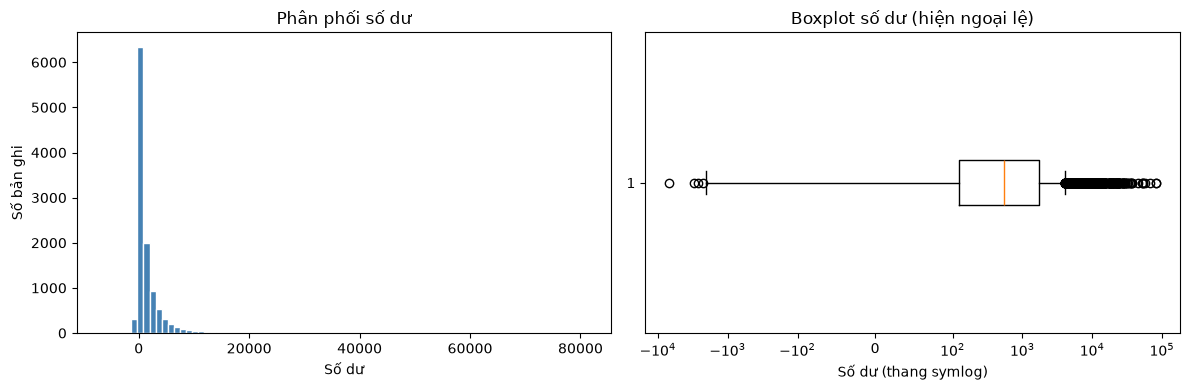

In [4]:
# Quan sát phân phối và ngoại lệ của số dư
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean['balance'], bins=80, color='steelblue', edgecolor='white')
axes[0].set(title='Phân phối số dư', xlabel='Số dư', ylabel='Số bản ghi')
axes[1].boxplot(clean['balance'], orientation='horizontal', showfliers=True)
axes[1].set_xscale('symlog', linthresh=100)
axes[1].set(title='Boxplot số dư (hiện ngoại lệ)', xlabel='Số dư (thang symlog)')
plt.tight_layout()
plt.show()
print(f"Số dư: trung bình {clean['balance'].mean():,.0f}, trung vị {clean['balance'].median():,.0f}; IQR đánh dấu {outliers['balance']:,} giá trị.")

Phân phối số dư lệch phải: trung bình khoảng 1.529 cao hơn trung vị 550, với đuôi kéo dài tới 81.204. Boxplot hiện ngoại lệ trên thang `symlog`, tuyến tính gần 0 và nén các giá trị có độ lớn cao. Cả 1.055 điểm ngoài IQR (9,45%) được giữ lại vì số dư âm hoặc lớn chưa có bằng chứng là lỗi ghi nhận.

Dữ liệu không có null hoặc bản ghi trùng hoàn toàn. Nhãn `unknown` xuất hiện ở `job` (70 dòng), `education` (497), `contact` (2.346; 21,02%) và `poutcome` (8.326; 74,59%).

Trong nhóm `poutcome = unknown`, 8.324 bản ghi chưa liên hệ trước (`pdays = -1`); hai bản ghi còn lại có ngày liên hệ nhưng chưa xác định kết quả. Sau tiền xử lý, 11.162 quan sát và các thuộc tính gốc được giữ nguyên.

## 3. Phân tích và trực quan hóa

Tỷ lệ đăng ký bằng số bản ghi `deposit = yes` chia cho tổng số bản ghi trong nhóm.

Hai kiểm định chi-square dùng mức ý nghĩa 5%:

- Tuổi: H₀ là kết quả đăng ký độc lập với nhóm tuổi; H₁ là có mối liên hệ.
- Vay nhà: H₀ là kết quả đăng ký độc lập với tình trạng vay nhà; H₁ là có mối liên hệ.

Bác bỏ H₀ khi p < 0,05. Các bảng được kiểm tra tần số kỳ vọng từ 5 trở lên; bảng vay nhà áp dụng hiệu chỉnh Yates. Suy luận dựa trên giả định các bản ghi độc lập, chưa xác minh được do thiếu mã khách hàng. Kết quả phản ánh mối liên hệ trong mẫu.

### EDA: cơ cấu mẫu và số lần liên hệ

Trước khi so sánh tỷ lệ đăng ký, xem xét thành phần khách hàng và mức độ liên hệ trong chiến dịch. Các bảng phân bố giữ riêng nhãn `unknown`.

In [5]:
# Phân bố học vấn, hình thức liên hệ và khoản vay cá nhân
profile_tables = []
for variable in ['education', 'contact', 'loan']:
    frequencies = clean[variable].value_counts(dropna=False)
    table = frequencies.rename_axis('Nhóm').reset_index(name='Số bản ghi')
    table.insert(0, 'Biến', variable)
    table['Tỷ lệ (%)'] = table['Số bản ghi'] / len(clean) * 100
    profile_tables.append(table)
profile = pd.concat(profile_tables, ignore_index=True)
display(profile)
assert profile.groupby('Biến')['Số bản ghi'].sum().eq(len(clean)).all()

,Biến,Nhóm,Số bản ghi,Tỷ lệ (%)
0,education,secondary,5476,49.059308
1,education,tertiary,3689,33.049633
2,education,primary,1500,13.438452
3,education,unknown,497,4.452607
4,contact,cellular,8042,72.048020
5,contact,unknown,2346,21.017739
6,contact,telephone,774,6.934241
7,loan,no,9702,86.919907
8,loan,yes,1460,13.080093


Nhóm `secondary` chiếm 49,1% mẫu; hình thức liên hệ `cellular` chiếm 72,0%. Khách hàng không có vay cá nhân chiếm 86,9%. Cơ cấu này cần được đối chiếu với khách hàng thực tế trước khi áp dụng kết quả cho chiến dịch khác; các tỷ trọng chưa giải thích nguyên nhân đăng ký.

Tuổi trung vị: 39; khoảng tuổi: 18–95.
Liên hệ 1–2 lần: 7,826 bản ghi (70.1%).
Trung vị số lần liên hệ: 2; lớn nhất: 63.


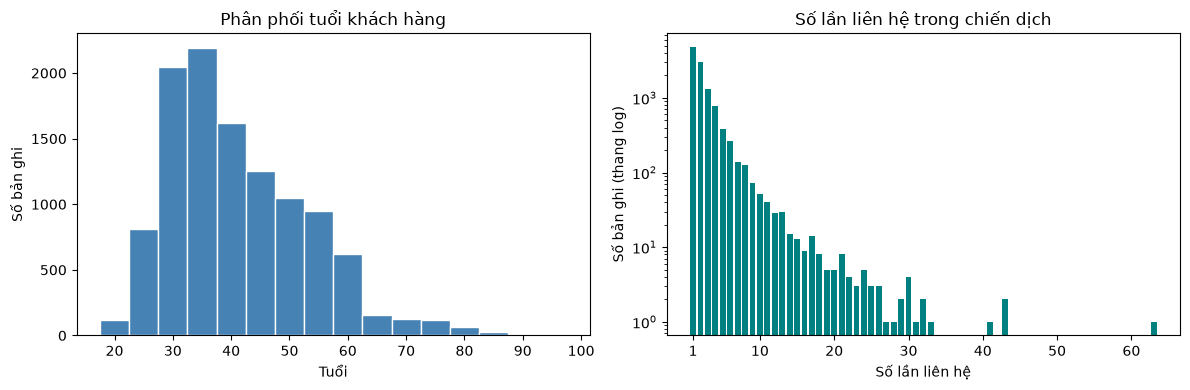

In [6]:
# Phân phối tuổi và số lần liên hệ trong chiến dịch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean['age'], bins=np.arange(17.5, 100, 5), color='steelblue', edgecolor='white')
axes[0].set(title='Phân phối tuổi khách hàng', xlabel='Tuổi', ylabel='Số bản ghi')
campaign_counts = clean['campaign'].value_counts().sort_index()
axes[1].bar(campaign_counts.index, campaign_counts.values, color='teal')
axes[1].set_yscale('log')
axes[1].set_xticks([1, 10, 20, 30, 40, 50, 60])
axes[1].set(title='Số lần liên hệ trong chiến dịch', xlabel='Số lần liên hệ', ylabel='Số bản ghi (thang log)')
plt.tight_layout()
plt.show()
print(f"Tuổi trung vị: {clean['age'].median():.0f}; khoảng tuổi: {clean['age'].min()}–{clean['age'].max()}.")
print(f"Liên hệ 1–2 lần: {clean['campaign'].le(2).sum():,} bản ghi ({clean['campaign'].le(2).mean():.1%}).")
print(f"Trung vị số lần liên hệ: {clean['campaign'].median():.0f}; lớn nhất: {clean['campaign'].max()}.")

Tuổi trung vị là 39; nhóm từ 31 đến 50 tuổi chiếm 59,9% mẫu. Số lần liên hệ lệch phải: 7.826 bản ghi (70,1%) được liên hệ 1–2 lần, trong khi giá trị lớn nhất là 63. Trục số bản ghi của biểu đồ liên hệ dùng thang log để thấy cả những tần số nhỏ. Các trường hợp liên hệ nhiều lần đáng được rà soát về chi phí, nhưng phân bố này chưa chứng minh giảm số cuộc gọi sẽ tăng hiệu quả.

deposit
no     5873
yes    5289
Name: count, dtype: int64
Tỷ lệ đăng ký (%): 47.4


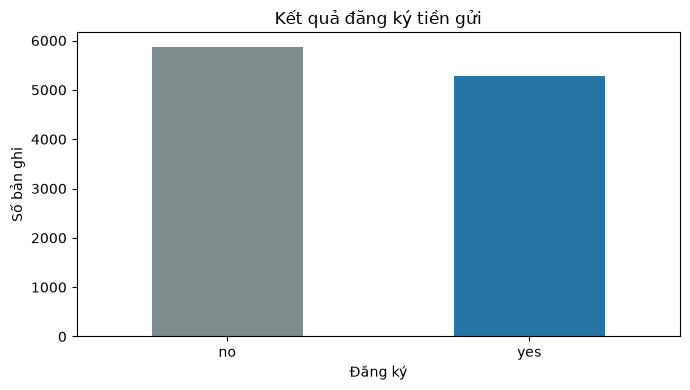

In [7]:
# Phân bố kết quả đăng ký
counts = clean['deposit'].value_counts().reindex(['no', 'yes'])
ax = counts.plot.bar(color=['#7f8c8d', '#2874a6'], rot=0, figsize=(7, 4))
ax.set(title='Kết quả đăng ký tiền gửi', xlabel='Đăng ký', ylabel='Số bản ghi')
plt.tight_layout()
plt.show()
print(counts)
print("Tỷ lệ đăng ký (%):", round(counts["yes"] / len(clean) * 100, 1))

Tỷ lệ đăng ký 47,4% là mốc so sánh các nhóm trong mẫu. Hai kết quả có quy mô tương đối gần nhau, nhưng tỷ lệ này chưa đại diện cho toàn bộ khách hàng hoặc chiến dịch mới.

Kiểm định chi-square: χ²=453.82, bậc tự do=4, p=6.48e-97; kỳ vọng nhỏ nhất=289.5.
Bác bỏ H0 ở mức ý nghĩa 5%.


,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
nhom_tuoi,,,
≤30,2007,1145,0.570503
31–40,4188,1812,0.432665
41–50,2496,1019,0.408253
51–60,1860,811,0.436022
>60,611,502,0.821604


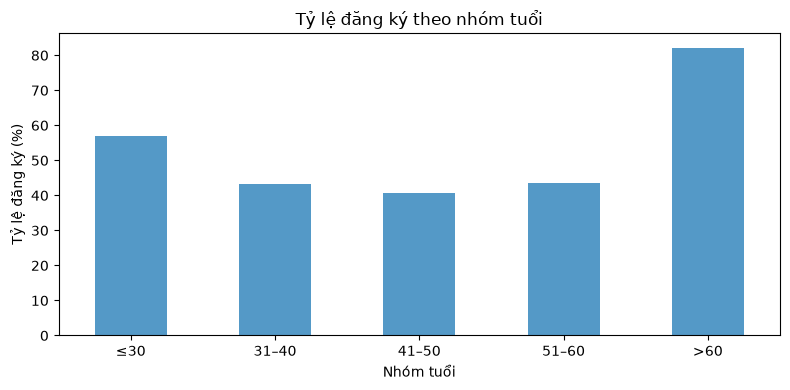

In [8]:
# So sánh tỷ lệ đăng ký theo nhóm tuổi
age_stats = clean.groupby('nhom_tuoi', observed=True)['deposit_yes'].agg(['size', 'sum', 'mean'])
display(age_stats.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (age_stats['mean'] * 100).plot.bar(color='#5499c7', rot=0, figsize=(8, 4))
ax.set(title='Tỷ lệ đăng ký theo nhóm tuổi', xlabel='Nhóm tuổi', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
table_age = pd.crosstab(clean['nhom_tuoi'], clean['deposit'])
chi, p_age, dof, expected = chi2_contingency(table_age)
print(f'Kiểm định chi-square: χ²={chi:.2f}, bậc tự do={dof}, p={p_age:.3g}; kỳ vọng nhỏ nhất={expected.min():.1f}.')
if p_age < 0.05:
    print('Bác bỏ H0 ở mức ý nghĩa 5%.')
else:
    print('Chưa đủ bằng chứng để bác bỏ H0 ở mức ý nghĩa 5%.')

Tỷ lệ đăng ký không tăng đều theo tuổi. Nhóm trên 60 đạt 82,2% nhưng chỉ có 611 bản ghi. Nhóm từ 31 đến 40 đạt 43,3% song đóng góp nhiều đăng ký nhất (1.812). Cần xem xét cả tỷ lệ và quy mô khi lựa chọn nhóm thử nghiệm.

Kiểm định bác bỏ H₀ ở mức 5%, cho thấy mối liên hệ tổng thể giữa nhóm tuổi và kết quả đăng ký. Kết quả chưa xác định tác động riêng của tuổi hoặc chênh lệch có ý nghĩa thống kê giữa từng cặp nhóm.

Kiểm định chi-square: χ²=463.19, bậc tự do=1, p=9.72e-103; kỳ vọng nhỏ nhất=2502.3.
Bác bỏ H0 ở mức ý nghĩa 5%.


,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
housing,,,
no,5881,3354,0.570311
yes,5281,1935,0.366408


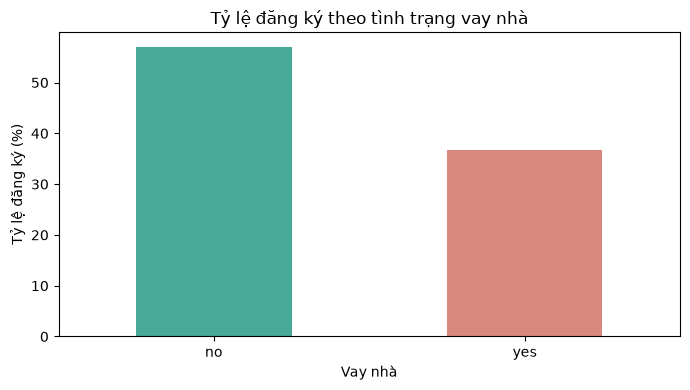

In [9]:
# So sánh theo tình trạng vay nhà
housing = clean.groupby('housing')['deposit_yes'].agg(['size', 'sum', 'mean'])
display(housing.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (housing['mean'] * 100).plot.bar(color=['#48a999', '#d98880'], rot=0, figsize=(7, 4))
ax.set(title='Tỷ lệ đăng ký theo tình trạng vay nhà', xlabel='Vay nhà', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
chi, p_housing, dof, expected = chi2_contingency(pd.crosstab(clean['housing'], clean['deposit']))
print(f'Kiểm định chi-square: χ²={chi:.2f}, bậc tự do={dof}, p={p_housing:.3g}; kỳ vọng nhỏ nhất={expected.min():.1f}.')
if p_housing < 0.05:
    print('Bác bỏ H0 ở mức ý nghĩa 5%.')
else:
    print('Chưa đủ bằng chứng để bác bỏ H0 ở mức ý nghĩa 5%.')

Nhóm không vay nhà đạt 57,0%, cao hơn nhóm có vay 20,4 điểm phần trăm. Khác biệt này gợi ý thử thông điệp theo nhóm; chưa có cơ sở giải thích bằng thu nhập hoặc áp lực trả nợ.

Kiểm định bác bỏ H₀ ở mức 5%. Chênh lệch quan sát chưa thể coi là tác động của việc vay nhà vì chưa kiểm soát các đặc điểm khác.

### EDA kết hợp: tuổi và tình trạng vay nhà

Tỷ lệ theo từng biến có thể phụ thuộc cơ cấu khách hàng. So sánh thêm tình trạng vay nhà trong từng nhóm tuổi, đồng thời hiển thị số quan sát để nhận diện nhóm ít dữ liệu.

Số bản ghi  Số đăng ký  Tỷ lệ đăng ký
nhom_tuoi housing                                       
≤30       no             1101         765       0.694823
          yes             906         380       0.419426
31–40     no             1817         949       0.522289
          yes            2371         863       0.363981
41–50     no             1239         585       0.472155
          yes            1257         434       0.345267
51–60     no             1161         593       0.510767
          yes             699         218       0.311874
>60       no              563         462       0.820604
          yes              48          40       0.833333

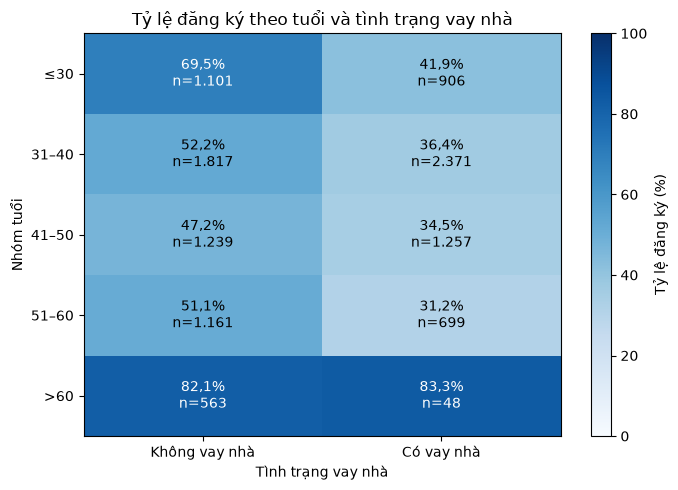

In [10]:
# Tỷ lệ đăng ký theo tuổi kết hợp tình trạng vay nhà
joint = clean.groupby(['nhom_tuoi', 'housing'], observed=True)['deposit_yes'].agg(['size', 'sum', 'mean'])
display(joint.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
joint_rates = joint['mean'].unstack('housing').reindex(columns=['no', 'yes']) * 100
joint_counts = joint['size'].unstack('housing').reindex(columns=['no', 'yes'])
fig, ax = plt.subplots(figsize=(7, 5))
heat = ax.imshow(joint_rates.to_numpy(), cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks([0, 1], ['Không vay nhà', 'Có vay nhà'])
ax.set_yticks(range(len(joint_rates)), joint_rates.index.astype(str))
ax.set(title='Tỷ lệ đăng ký theo tuổi và tình trạng vay nhà', xlabel='Tình trạng vay nhà', ylabel='Nhóm tuổi')
for row in range(len(joint_rates)):
    for col in range(2):
        value = joint_rates.iloc[row, col]
        count = int(joint_counts.iloc[row, col])
        label = f'{value:.1f}'.replace('.', ',') + '%\n' + 'n=' + f'{count:,}'.replace(',', '.')
        ax.text(col, row, label, ha='center', va='center', color='white' if value >= 60 else 'black')
fig.colorbar(heat, ax=ax, label='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
assert joint['size'].sum() == len(clean)
assert joint['sum'].sum() == clean['deposit_yes'].sum()

Trong bốn nhóm tuổi không quá 60, nhóm không vay nhà đều có tỷ lệ đăng ký cao hơn nhóm có vay. Chẳng hạn, ở nhóm không quá 30 tuổi, hai tỷ lệ lần lượt là 69,5% và 41,9%.

Ở nhóm trên 60 tuổi, tỷ lệ của người có vay là 83,3%, gần mức 82,1% của người không vay. Tuy nhiên, nhóm có vay chỉ có 48 bản ghi, so với 563 ở nhóm không vay. Kết quả gộp 57,0% và 36,6% vì vậy không mô tả giống nhau ở mọi độ tuổi. Đây là so sánh mô tả, chưa phải kiểm định tương tác hoặc bằng chứng về tác động riêng của khoản vay.

Trong nhóm unknown: 8,324 chưa liên hệ trước; 2 có ngày liên hệ nhưng chưa xác định kết quả trước.


,Số bản ghi,Số đăng ký,Tỷ lệ đăng ký
poutcome,,,
success,1071,978,0.913165
other,537,307,0.571695
failure,1228,618,0.503257
unknown,8326,3386,0.406678


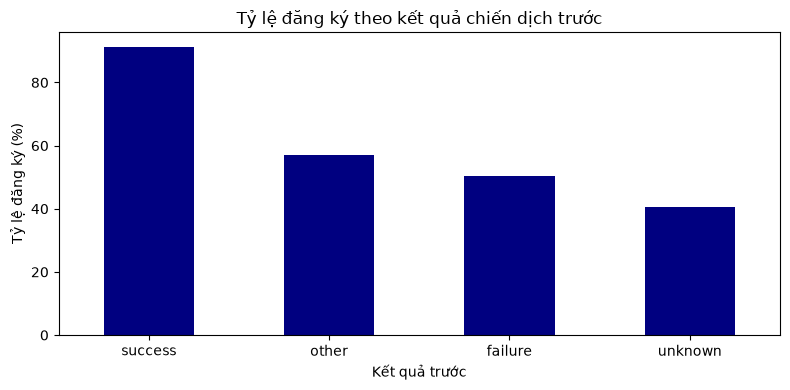

In [11]:
# Phân tích kết quả chiến dịch trước
previous = clean.groupby('poutcome')['deposit_yes'].agg(['size', 'sum', 'mean']).sort_values('mean', ascending=False)
display(previous.rename(columns={'size': 'Số bản ghi', 'sum': 'Số đăng ký', 'mean': 'Tỷ lệ đăng ký'}))
ax = (previous['mean'] * 100).plot.bar(color='navy', rot=0, figsize=(8, 4))
ax.set(title='Tỷ lệ đăng ký theo kết quả chiến dịch trước', xlabel='Kết quả trước', ylabel='Tỷ lệ đăng ký (%)')
plt.tight_layout()
plt.show()
unknown_history = clean[clean['poutcome'] == 'unknown']['pdays']
print(f"Trong nhóm unknown: {(unknown_history == -1).sum():,} chưa liên hệ trước; {(unknown_history != -1).sum():,} có ngày liên hệ nhưng chưa xác định kết quả trước.")

Nhóm `success` có tỷ lệ đăng ký cao nhất (91,3%), trong khi nhóm `unknown` đóng góp nhiều đăng ký nhất (3.386) do quy mô lớn. Phần lớn nhóm `unknown` chưa liên hệ trước nên không dùng trực tiếp làm đối chứng cho nhóm từng thành công. Nhóm `failure` vẫn có 618 đăng ký, cho thấy không nên dùng kết quả trước làm tiêu chí duy nhất lựa chọn khách hàng.

Tỷ lệ 91,3% là kết quả mô tả, chưa phải hiệu quả của việc liên hệ lại.

Trung vị số dư theo kết quả đăng ký:
deposit
no     414.0
yes    733.0
Name: balance, dtype: float64


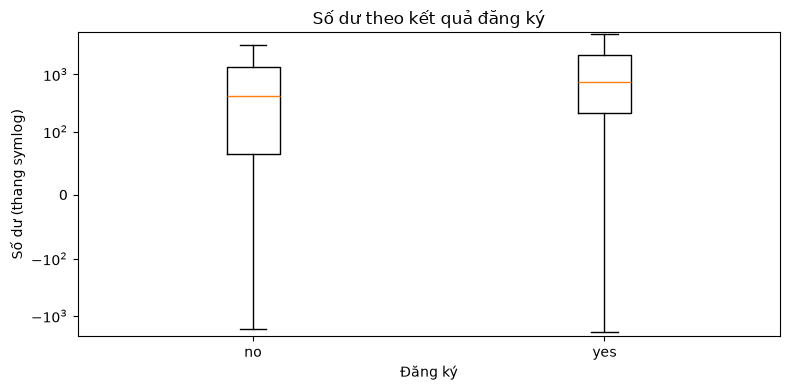

,Q1,Trung vị,Q3
deposit,,,
no,64.0,414.0,1324.0
yes,210.0,733.0,2159.0


In [12]:
# Phân phối số dư theo kết quả, dùng thang đối xứng để giữ cả số âm
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([clean.loc[clean['deposit'] == v, 'balance'] for v in ['no', 'yes']], showfliers=False)
ax.set_xticks([1, 2], ['no', 'yes'])
ax.set_yscale('symlog', linthresh=100)
ax.set(title='Số dư theo kết quả đăng ký', xlabel='Đăng ký', ylabel='Số dư (thang symlog)')
plt.tight_layout()
plt.show()
balance_quantiles = clean.groupby('deposit')['balance'].quantile([0.25, 0.5, 0.75]).unstack()
balance_quantiles.columns = ['Q1', 'Trung vị', 'Q3']
display(balance_quantiles)
med = clean.groupby('deposit')['balance'].median()
print("Trung vị số dư theo kết quả đăng ký:")
print(med)

Trung vị số dư nhóm đăng ký cao hơn 319 đơn vị. Q1 và Q3 cũng cao hơn, nhưng hai khoảng tứ phân vị chồng lấn; chưa có cơ sở đặt ngưỡng lựa chọn khách hàng từ boxplot này.

Hình dùng thang `symlog` và ẩn các điểm ngoài râu để dễ quan sát. Toàn bộ quan sát vẫn được giữ trong tính toán; so sánh này mang tính mô tả, chưa có kiểm định riêng.

## 4. Khuyến nghị và giới hạn

Thử thông điệp theo nhóm tuổi hoặc tình trạng vay nhà, phân bổ ngẫu nhiên trong từng nhóm vào phương án hiện tại và phương án điều chỉnh. Với khách hàng từng thành công, thử liên hệ bổ sung so với đối chứng trong cùng nhóm đủ điều kiện, ghi nhận cả đăng ký tự phát.

So sánh tỷ lệ đăng ký trên toàn bộ khách hàng được phân vào mỗi phương án, trong cùng thời hạn. Đọc chi phí mỗi đăng ký cùng chênh lệch tỷ lệ so với đối chứng trước khi cân nhắc mở rộng.

Phân tích kết hợp tuổi với vay nhà cho thấy cần đọc kết quả gộp cùng cơ cấu nhóm. Các kết quả vẫn chỉ mô tả mẫu, chưa kiểm soát đồng thời nhiều đặc điểm hoặc xác minh được khách hàng lặp lại. Thiếu thời điểm, chi phí và lợi nhuận nên chưa đánh giá được tác động kinh tế. Các thử nghiệm trên là đề xuất, chưa được thực hiện.

Có thể bổ sung mã khách hàng ẩn danh, thời điểm và chi phí; mở rộng phân tích kết hợp sang các đặc điểm khác và xem xét thêm khoảng tin cậy. Nếu xây mô hình trước cuộc gọi, cần kiểm tra thời điểm có sẵn của biến, loại `duration` và chia dữ liệu trước các bước tiền xử lý cần học từ dữ liệu.